In [2]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt

# Find the project root, whichever folder the kernel started in
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
PARQUET = ROOT / "data" / "parquet"
print("Reading data from:", PARQUET)

con = duckdb.connect()
con.execute(f"""
    CREATE VIEW app AS
    SELECT * FROM '{PARQUET / "application_train.parquet"}'
""")



Reading data from: /home/fiza/Credit_Risk/data/parquet


In [3]:
con.sql("""
    SELECT MIN(DAYS_BIRTH), MAX(DAYS_BIRTH),
           MIN(DAYS_EMPLOYED), MAX(DAYS_EMPLOYED)
    FROM app
""")


min(DAYS_BIRTH)BIGINT,max(DAYS_BIRTH)BIGINT,min(DAYS_EMPLOYED)BIGINT,max(DAYS_EMPLOYED)BIGINT
-25229,-7489,-17912,365243


In [4]:
con.sql("""
    SELECT NAME_INCOME_TYPE, COUNT(*) AS n
    FROM app
    WHERE DAYS_EMPLOYED = 365243
    GROUP BY NAME_INCOME_TYPE
""")


NAME_INCOME_TYPEVARCHAR,nBIGINT
Pensioner,55352
Unemployed,22


In [5]:
con.sql("""
    SELECT DAYS_EMPLOYED = 365243 AS is_placeholder,
           COUNT(*) AS n,
           ROUND(AVG(TARGET) * 100, 2) AS default_rate
    FROM app
    GROUP BY 1
""")


is_placeholderBOOLEAN,nBIGINT,default_rateDOUBLE
False,252137,8.66
True,55374,5.4



### Finding: DAYS_EMPLOYED = 365243 is a placeholder

- `DAYS_EMPLOYED` should be negative (days before the application), but its maximum is **365243**, about **1,000 years in the future**. That's impossible, so it's a placeholder code, not a real value.
- **55,374 applicants (18%)** have it: **55,352 pensioners + 22 unemployed**. These are people without a current job, so there's no employment start date.
- They default **less**: **5.4%** vs **8.66%** for everyone else, because a pension is a steady income.
- **Cleaning plan:** replace 365243 with `NULL` **and** add a flag column `DAYS_EMPLOYED_ANOM` (1 = placeholder). Just setting it to null would lose the useful "pensioner = lower risk" signal.


In [6]:
missing = con.sql("SUMMARIZE app").df()
missing = missing[["column_name", "null_percentage"]]
missing["null_percentage"] = missing["null_percentage"].astype(float)
missing = missing.sort_values("null_percentage", ascending=False)
missing.head(55)


,column_name,null_percentage
48,COMMONAREA_AVG,69.87
62,COMMONAREA_MODE,69.87
76,COMMONAREA_MEDI,69.87
84,NONLIVINGAPARTMENTS_MEDI,69.43
70,NONLIVINGAPARTMENTS_MODE,69.43
56,NONLIVINGAPARTMENTS_AVG,69.43
86,FONDKAPREMONT_MODE,68.39
54,LIVINGAPARTMENTS_AVG,68.35
82,LIVINGAPARTMENTS_MEDI,68.35
68,LIVINGAPARTMENTS_MODE,68.35


In [7]:
for t in [40, 50, 60]:
    print(f"> {t}% missing: {(missing['null_percentage'] > t).sum()} columns")


> 40% missing: 49 columns
> 50% missing: 41 columns
> 60% missing: 17 columns


### Finding: missing values
- 41 columns are >50% missing (matches the report's "dropped 41 columns").
- **But EXT_SOURCE_1 (56% missing) is one of the top-3 predictors**, so dropping it blindly would be a mistake.
- Decision: drop the >50% columns **except EXT_SOURCE_1** → 40 dropped. Most are redundant building stats (_AVG/_MODE/_MEDI).
- WoE binning will treat "missing" as its own bin, so we don't need to fill it in.
- OWN_CAR_AGE is missing mostly because the person has no car (structural missingness).


In [8]:
con.sql("""
    SELECT EXT_SOURCE_1 IS NULL AS is_missing,
           COUNT(*) AS n,
           ROUND(AVG(TARGET) * 100, 2) AS default_rate
    FROM app
    GROUP BY 1
""")


is_missingBOOLEAN,nBIGINT,default_rateDOUBLE
True,173378,8.52
False,134133,7.5


### Finding: missing EXT_SOURCE_1 is a risk signal
- Missing: 8.52% default vs present: 7.50%, so missing applicants are ~14% riskier.
- Likely reason: no external credit record means a thinner financial history.
- Decision: keep the column; WoE binning will give "missing" its own bin.


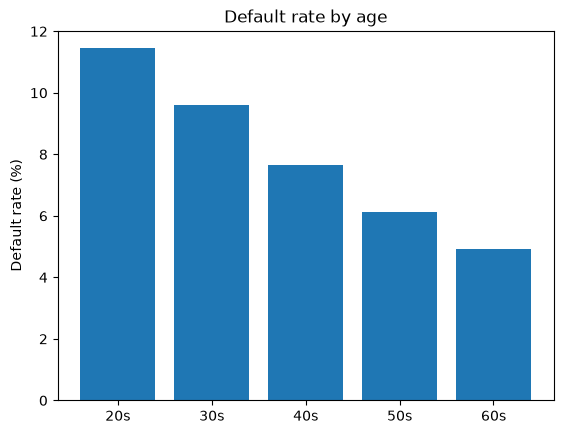

,age_band,n,default_rate
0,20.0,45186,11.443810
1,30.0,82331,9.591770
2,40.0,76599,7.641092
3,50.0,68094,6.120950
4,60.0,35301,4.917708


In [9]:
age = con.sql("""
    SELECT FLOOR(-DAYS_BIRTH / 365.25 / 10) * 10 AS age_band,
           COUNT(*) AS n,
           AVG(TARGET) * 100 AS default_rate
    FROM app
    GROUP BY 1
    ORDER BY 1
""").df()

plt.bar(age["age_band"].astype(int).astype(str) + "s", age["default_rate"])
plt.ylabel("Default rate (%)")
plt.title("Default rate by age")
plt.show()

age


### Finding: age vs default
- Default rate falls steadily with age: 11.4% (20s) → 4.9% (60s), about 2.3x.
- The pattern is **monotonic**, which suits a scorecard: older = more points.
- Note: age is a regulated variable in real lending.


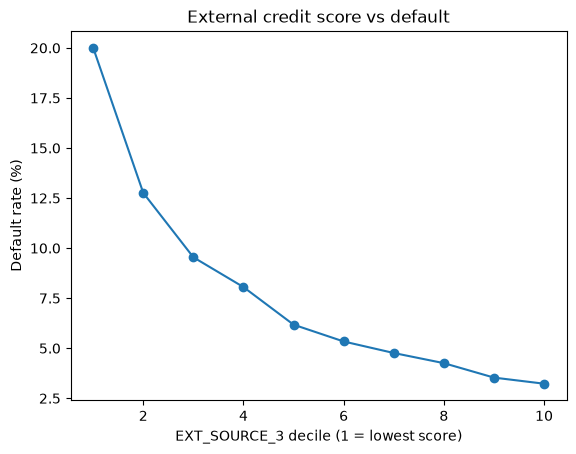

,decile,n,default_rate
0,1,24655,20.012168
1,2,24655,12.760089
2,3,24655,9.543703
3,4,24655,8.055161
4,5,24655,6.177246
5,6,24655,5.337660
6,7,24654,4.761905
7,8,24654,4.254888
8,9,24654,3.532895
9,10,24654,3.228685


In [10]:
ext = con.sql("""
    WITH ranked AS (
        SELECT TARGET,
               NTILE(10) OVER (ORDER BY EXT_SOURCE_3) AS decile
        FROM app
        WHERE EXT_SOURCE_3 IS NOT NULL
    )
    SELECT decile, COUNT(*) AS n, AVG(TARGET) * 100 AS default_rate
    FROM ranked
    GROUP BY decile
    ORDER BY decile
""").df()

plt.plot(ext["decile"], ext["default_rate"], marker="o")
plt.xlabel("EXT_SOURCE_3 decile (1 = lowest score)")
plt.ylabel("Default rate (%)")
plt.title("External credit score vs default")
plt.show()

ext


## Key findings

1. **Target:** 307,511 applicants, 24,825 defaults (**8.07%**). The data is imbalanced, roughly 11 good customers for every bad one.
2. **DAYS_EMPLOYED = 365243** is a placeholder for 55,374 pensioners/unemployed, who default *less* (5.4% vs 8.66%). Plan: set to NULL **and** add a flag column.
3. **Missing values:** 41 columns are >50% missing, but that includes **EXT_SOURCE_1**, a top-3 predictor. Plan: drop the 40 others (mostly redundant building stats) and keep EXT_SOURCE_1.
4. **Missingness is informative:** applicants missing EXT_SOURCE_1 default more (8.52% vs 7.50%). WoE binning will give "missing" its own bin.
5. **Age:** default falls steadily from 11.4% (20s) to 4.9% (60s), a monotonic pattern.
6. **EXT_SOURCE_3:** default falls from 20.0% (lowest decile) to 3.2% (highest), about **6x**, so it's a much stronger predictor than age. The curve is steep at the low end, which WoE binning can capture and a straight line can't.
